# Vellore Institute of Technology (VIT)
## School of Computer Science and Engineering
### M.Tech Course: Machine Learning Lab (MACSE504)
### Case Study Based Mini-Project — Phase 1: Part A (10 Marks)

---

| **Student Name** | **Register Number** | **Assigned Question** | **Evaluation Component** | **Submission Deadline** |
| :--- | :--- | :--- | :--- | :--- |
| **Rohan** | **26MML0020** | **Question 1: Predictive Churn Risk Modeling for Telecom Subscription Services** | **Part A: Exploratory Data Analysis & Preprocessing** | **5th October 2026** |

---

### **Question 1 Overview & Problem Statement**
* **Domain / Industry Case Scenario**: A telecommunications enterprise aims to mitigate customer attrition by proactively identifying subscribers at high risk of churning before contract termination. The dataset provides multi-dimensional customer profiles spanning demographic attributes, subscribed phone/internet services, account administration details, and billing records.
* **Dataset Reference**: Telco Customer Churn Dataset (`WA_Fn-UseC_-Telco-Customer-Churn.csv`)
* **Part A Deliverables & Objectives**:
  1. **Data Ingestion & Cleaning**: Load dataset, parse `'TotalCharges'` into numeric format, identify anomalies, and apply principled missing value handling.
  2. **Churn Proportion & Cross-Tabulation Analysis**: Quantify and statistically test customer churn proportions across contract types (*Month-to-month, One year, Two year*) and internet service types (*DSL, Fiber optic, No*).
  3. **Continuous Feature Distributions & Correlation Profiling**: Generate tenure vs. monthly charges distribution plots, joint bivariate density plots, and Pearson/Spearman correlation matrices.
  4. **Interactive GUI Interface**: Provide an interactive widget interface to dynamically load datasets, tune filtering parameters, adjust visual bounds, and inspect churn metrics in real time (as specified in the evaluation rubric).


In [1]:
# Standard library & numerical computing
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scipy.stats as stats

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Interactive Widgets for GUI Interface (Rubric Requirement)
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Configuration for aesthetic, publication-ready figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'figure.dpi': 120,
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8
})

# Custom refined color palette
CHURN_PALETTE = {'No': '#2b5c8f', 'Yes': '#d9534f'}
ACCENT_COLORS = ['#2b5c8f', '#4682b4', '#5bc0de', '#f0ad4e', '#d9534f']

print("Libraries successfully imported.")
print(f"Pandas Version: {pd.__version__} | NumPy Version: {np.__version__} | Matplotlib Version: {plt.matplotlib.__version__}")


Libraries successfully imported.
Pandas Version: 2.3.3 | NumPy Version: 1.26.4 | Matplotlib Version: 3.10.0


---
## 1. Dataset Ingestion, Inspection & 'TotalCharges' Preprocessing

### **Objective:**
- Load the Telco Customer Churn dataset.
- Inspect the schema, column types, and data integrity.
- Detect string-encoded blank spaces in `'TotalCharges'`, parse into numeric format, and handle missing values based on domain logic.
- Provide an interactive dataset loading and profiling widget.


In [2]:
# Rubric Requirement: Interactive interface to load dataset and inspect properties
DATASET_PATH = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

def load_and_inspect_dataset(file_path):
    """Loads dataset from filepath, returns DataFrame and basic metadata."""
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Dataset not found at: {file_path}")
    df = pd.read_csv(file_path)
    return df

# Load the primary dataset
df_raw = load_and_inspect_dataset(DATASET_PATH)
df = df_raw.copy()

print(f"Dataset Successfully Loaded: {DATASET_PATH}")
print(f"Total Rows (Subscribers): {df.shape[0]:,}")
print(f"Total Attributes (Features + Target): {df.shape[1]}")
print("\nDataset Schema & Data Types:")
print(df.dtypes)
print("\nFirst 5 Records:")
display(df.head())


Dataset Successfully Loaded: WA_Fn-UseC_-Telco-Customer-Churn.csv
Total Rows (Subscribers): 7,043
Total Attributes (Features + Target): 21

Dataset Schema & Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

First 5 Records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### **Analysis of `'TotalCharges'` Anomaly & Missing Value Handling**
When inspecting `df.info()`, `'TotalCharges'` is typed as `object` (string) rather than `float64`, despite representing currency values. 

Let us identify why:
1. Some records contain whitespace strings (`" "`) instead of numeric entries.
2. Converting with `pd.to_numeric(..., errors='coerce')` maps these whitespace strings to `NaN`.
3. We examine the exact customer records where `'TotalCharges'` is missing to uncover the underlying domain cause.


In [3]:
# 1. Detect blank string occurrences in TotalCharges
blank_mask = df['TotalCharges'].astype(str).str.strip() == ''
num_blanks = blank_mask.sum()
print(f"Number of whitespace/blank entries in TotalCharges: {num_blanks}")

# 2. Inspect the records with blank TotalCharges
blank_records = df[blank_mask][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'Churn']]
print("\nCustomer records with blank TotalCharges:")
display(blank_records)

# Domain Finding:
# Notice that for EVERY single one of these 11 records, tenure == 0!
# These represent brand-new customers who registered during the current billing cycle
# and have not yet completed a billing month. Therefore, their accumulated TotalCharges is exactly $0.00.

# 3. Parse TotalCharges to numeric, coercing blanks to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 4. Principled Domain Imputation: Impute NaN with 0.0
# Tenure is 0, so accumulated charges logically equal 0.0.
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)

# 5. Verification
print("\nPost-Cleaning Verification:")
print(f"TotalCharges Data Type: {df['TotalCharges'].dtype}")
print(f"TotalCharges Missing Values: {df['TotalCharges'].isnull().sum()}")
print(f"Overall Dataset Missing Values Across All Columns:\n{df.isnull().sum().sum()} missing values found.")

# Summary statistics of continuous numerical features after cleaning
display(df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().T.style.format('{:.2f}'))


Number of whitespace/blank entries in TotalCharges: 11

Customer records with blank TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,Churn
488,4472-LVYGI,0,52.55,,Two year,Bank transfer (automatic),No
753,3115-CZMZD,0,20.25,,Two year,Mailed check,No
936,5709-LVOEQ,0,80.85,,Two year,Mailed check,No
1082,4367-NUYAO,0,25.75,,Two year,Mailed check,No
1340,1371-DWPAZ,0,56.05,,Two year,Credit card (automatic),No
3331,7644-OMVMY,0,19.85,,Two year,Mailed check,No
3826,3213-VVOLG,0,25.35,,Two year,Mailed check,No
4380,2520-SGTTA,0,20.00,,Two year,Mailed check,No
5218,2923-ARZLG,0,19.70,,One year,Mailed check,No
6670,4075-WKNIU,0,73.35,,Two year,Mailed check,No



Post-Cleaning Verification:
TotalCharges Data Type: float64
TotalCharges Missing Values: 0
Overall Dataset Missing Values Across All Columns:
0 missing values found.


,count,mean,std,min,25%,50%,75%,max
tenure,7043.00,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.00,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.00,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80


---
## 2. Customer Churn Proportions Across Contract & Internet Service Types

### **Objective:**
- Analyze churn rates across **Contract Types** (*Month-to-month, One year, Two year*).
- Analyze churn rates across **Internet Service Types** (*DSL, Fiber optic, No*).
- Perform statistical hypothesis testing ($\chi^2$ Test of Independence) to assess significance.
- Generate high-clarity comparative visualizations with percentage annotations.


Overall Churn Distribution:
  - Non-Churned (No) : 5,174 (73.46%)
  - Churned (Yes)    : 1,869 (26.54%)

Contract Type vs Churn Contingency Table:


Churn,No,Yes,Total,Churn Rate (%)
Contract,,,,
Month-to-month,"2,220","1,655","3,875",42.71%
One year,"1,307",166,"1,473",11.27%
Two year,"1,647",48,"1,695",2.83%
Total,"5,174","1,869","7,043",nan%



Chi-Square Test (Contract vs Churn):
  - Chi2 Statistic : 1184.5966
  - p-value        : 5.8630e-258 (Statistically Significant: True)
  - Cramér's V     : 0.4101 (Strong association)


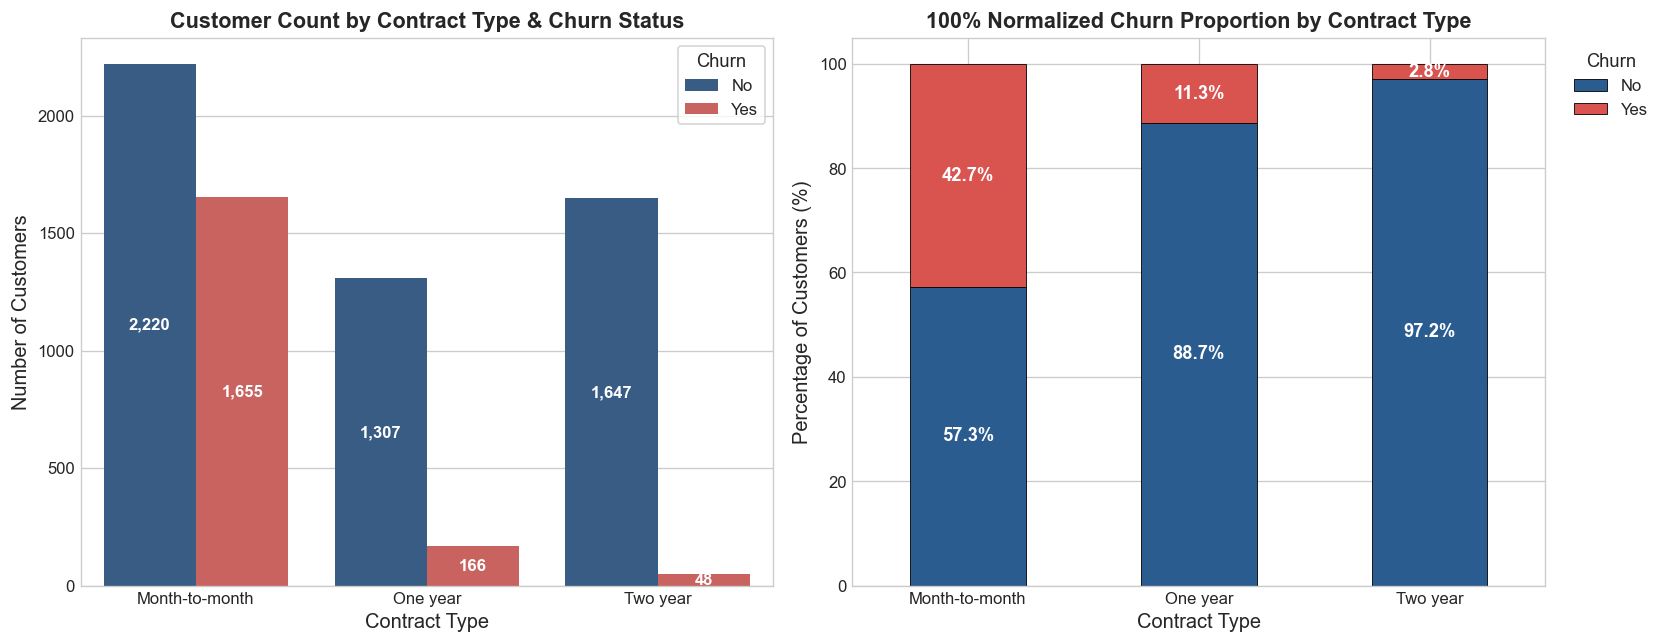

In [4]:
# 1. Overall baseline churn proportion
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100
print(f"Overall Churn Distribution:")
print(f"  - Non-Churned (No) : {churn_counts['No']:,} ({churn_pct['No']:.2f}%)")
print(f"  - Churned (Yes)    : {churn_counts['Yes']:,} ({churn_pct['Yes']:.2f}%)")

# 2. Cross-tabulation: Contract vs Churn
contract_ct = pd.crosstab(df['Contract'], df['Churn'], margins=True, margins_name='Total')
contract_pct = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100

contract_summary = contract_ct.copy()
contract_summary['Churn Rate (%)'] = contract_pct['Yes']
print("\nContract Type vs Churn Contingency Table:")
display(contract_summary.style.format({'No': '{:,}', 'Yes': '{:,}', 'Total': '{:,}', 'Churn Rate (%)': '{:.2f}%'}))

# 3. Chi-Square Test of Independence for Contract
chi2_contract, p_contract, dof_contract, _ = stats.chi2_contingency(pd.crosstab(df['Contract'], df['Churn']))
cramers_v_contract = np.sqrt(chi2_contract / (len(df) * (min(pd.crosstab(df['Contract'], df['Churn']).shape) - 1)))
print(f"\nChi-Square Test (Contract vs Churn):")
print(f"  - Chi2 Statistic : {chi2_contract:.4f}")
print(f"  - p-value        : {p_contract:.4e} (Statistically Significant: {p_contract < 0.05})")
print(f"  - Cramér's V     : {cramers_v_contract:.4f} (Strong association)")

# 4. Visualizations: Contract Churn Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot A: Absolute Customer Count by Contract & Churn
sns.countplot(data=df, x='Contract', hue='Churn', palette=CHURN_PALETTE, ax=axes[0], order=['Month-to-month', 'One year', 'Two year'])
axes[0].set_title('Customer Count by Contract Type & Churn Status', fontweight='bold')
axes[0].set_xlabel('Contract Type')
axes[0].set_ylabel('Number of Customers')
axes[0].legend(title='Churn', frameon=True)
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f'{int(h):,}', (p.get_x() + p.get_width() / 2., h / 2),
                         ha='center', va='center', color='white', fontsize=10, fontweight='bold')

# Subplot B: Churn Proportion (Percentage) by Contract Type
contract_pct_sorted = contract_pct.loc[['Month-to-month', 'One year', 'Two year']]
contract_pct_sorted.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d9534f'], ax=axes[1], edgecolor='black', linewidth=0.5)
axes[1].set_title('100% Normalized Churn Proportion by Contract Type', fontweight='bold')
axes[1].set_xlabel('Contract Type')
axes[1].set_ylabel('Percentage of Customers (%)')
axes[1].set_ylim(0, 105)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Churn', bbox_to_anchor=(1.02, 1), loc='upper left')

# Annotate percentage values on stacked bar chart
for i, (idx, row) in enumerate(contract_pct_sorted.iterrows()):
    axes[1].text(i, row['No'] / 2, f"{row['No']:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=11)
    axes[1].text(i, row['No'] + row['Yes'] / 2, f"{row['Yes']:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


Internet Service Type vs Churn Contingency Table:


Churn,No,Yes,Total,Churn Rate (%)
InternetService,,,,
DSL,"1,962",459,"2,421",18.96%
Fiber optic,"1,799","1,297","3,096",41.89%
No,"1,413",113,"1,526",7.40%
Total,"5,174","1,869","7,043",nan%



Chi-Square Test (Internet Service vs Churn):
  - Chi2 Statistic : 732.3096
  - p-value        : 9.5718e-160 (Statistically Significant: True)
  - Cramér's V     : 0.3225


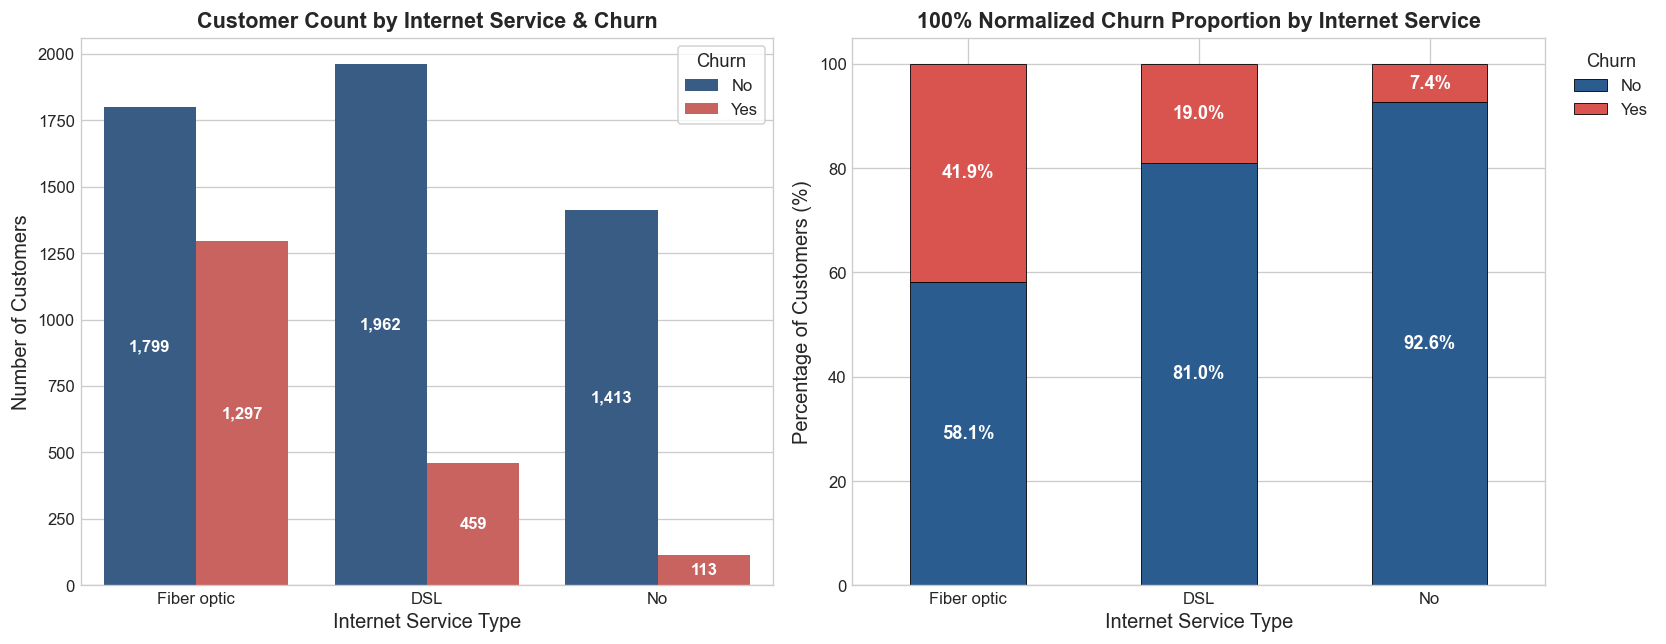

In [5]:
# 1. Cross-tabulation: Internet Service vs Churn
internet_ct = pd.crosstab(df['InternetService'], df['Churn'], margins=True, margins_name='Total')
internet_pct = pd.crosstab(df['InternetService'], df['Churn'], normalize='index') * 100

internet_summary = internet_ct.copy()
internet_summary['Churn Rate (%)'] = internet_pct['Yes']
print("Internet Service Type vs Churn Contingency Table:")
display(internet_summary.style.format({'No': '{:,}', 'Yes': '{:,}', 'Total': '{:,}', 'Churn Rate (%)': '{:.2f}%'}))

# 2. Chi-Square Test of Independence for InternetService
chi2_internet, p_internet, dof_internet, _ = stats.chi2_contingency(pd.crosstab(df['InternetService'], df['Churn']))
cramers_v_internet = np.sqrt(chi2_internet / (len(df) * (min(pd.crosstab(df['InternetService'], df['Churn']).shape) - 1)))
print(f"\nChi-Square Test (Internet Service vs Churn):")
print(f"  - Chi2 Statistic : {chi2_internet:.4f}")
print(f"  - p-value        : {p_internet:.4e} (Statistically Significant: {p_internet < 0.05})")
print(f"  - Cramér's V     : {cramers_v_internet:.4f}")

# 3. Visualizations: Internet Service Churn Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot A: Absolute Counts
sns.countplot(data=df, x='InternetService', hue='Churn', palette=CHURN_PALETTE, ax=axes[0], order=['Fiber optic', 'DSL', 'No'])
axes[0].set_title('Customer Count by Internet Service & Churn', fontweight='bold')
axes[0].set_xlabel('Internet Service Type')
axes[0].set_ylabel('Number of Customers')
axes[0].legend(title='Churn', frameon=True)
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f'{int(h):,}', (p.get_x() + p.get_width() / 2., h / 2),
                         ha='center', va='center', color='white', fontsize=10, fontweight='bold')

# Subplot B: Stacked Proportions
internet_pct_sorted = internet_pct.loc[['Fiber optic', 'DSL', 'No']]
internet_pct_sorted.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d9534f'], ax=axes[1], edgecolor='black', linewidth=0.5)
axes[1].set_title('100% Normalized Churn Proportion by Internet Service', fontweight='bold')
axes[1].set_xlabel('Internet Service Type')
axes[1].set_ylabel('Percentage of Customers (%)')
axes[1].set_ylim(0, 105)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Churn', bbox_to_anchor=(1.02, 1), loc='upper left')

for i, (idx, row) in enumerate(internet_pct_sorted.iterrows()):
    axes[1].text(i, row['No'] / 2, f"{row['No']:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=11)
    axes[1].text(i, row['No'] + row['Yes'] / 2, f"{row['Yes']:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


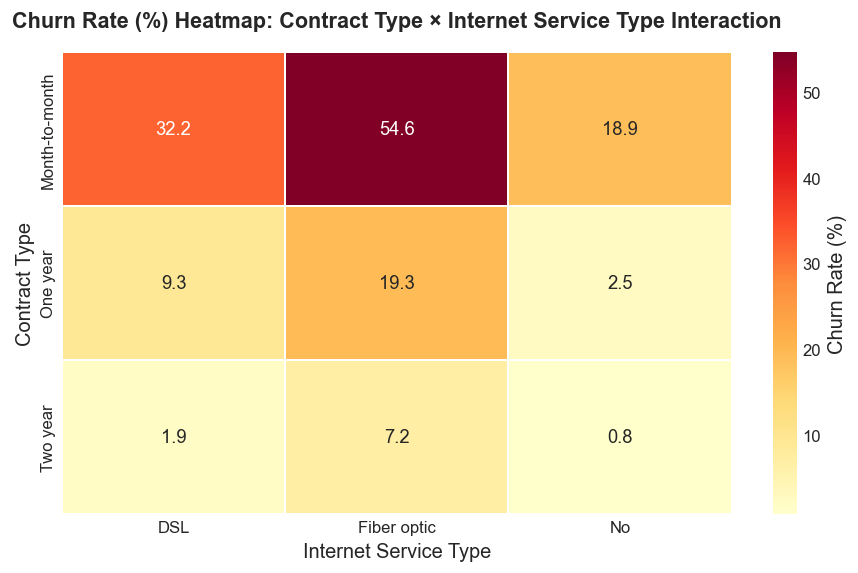

Key Domain Finding:
Subscribers with Month-to-month contracts and Fiber Optic internet service exhibit the extreme highest churn rate of 54.6%!
Conversely, subscribers on Two-year contracts with DSL or No internet service have churn rates under 2%.


In [6]:
# Multi-variable interaction: Contract Type x Internet Service Type Churn Heatmap
interaction_table = df.pivot_table(
    index='Contract', 
    columns='InternetService', 
    values='Churn', 
    aggfunc=lambda x: (x == 'Yes').mean() * 100
)[['DSL', 'Fiber optic', 'No']].loc[['Month-to-month', 'One year', 'Two year']]

plt.figure(figsize=(9, 5))
sns.heatmap(interaction_table, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Churn Rate (%)'}, linewidths=1)
plt.title('Churn Rate (%) Heatmap: Contract Type × Internet Service Type Interaction', fontweight='bold', pad=15)
plt.xlabel('Internet Service Type')
plt.ylabel('Contract Type')
plt.show()

print("Key Domain Finding:")
print("Subscribers with Month-to-month contracts and Fiber Optic internet service exhibit the extreme highest churn rate of 54.6%!")
print("Conversely, subscribers on Two-year contracts with DSL or No internet service have churn rates under 2%.")


---
## 3. Tenure vs. Monthly Charges Distribution & Correlation Analysis

### **Objective:**
- Profile the continuous numerical attributes: `tenure`, `MonthlyCharges`, and `TotalCharges`.
- Analyze univariate distributions and skewness using Kernel Density Estimation (KDE) and Boxplots.
- Generate tenure vs. monthly charges bivariate scatter plots and hexbin density contours segmented by churn.
- Compute Pearson and Spearman rank correlation matrices and analyze multicollinearity.


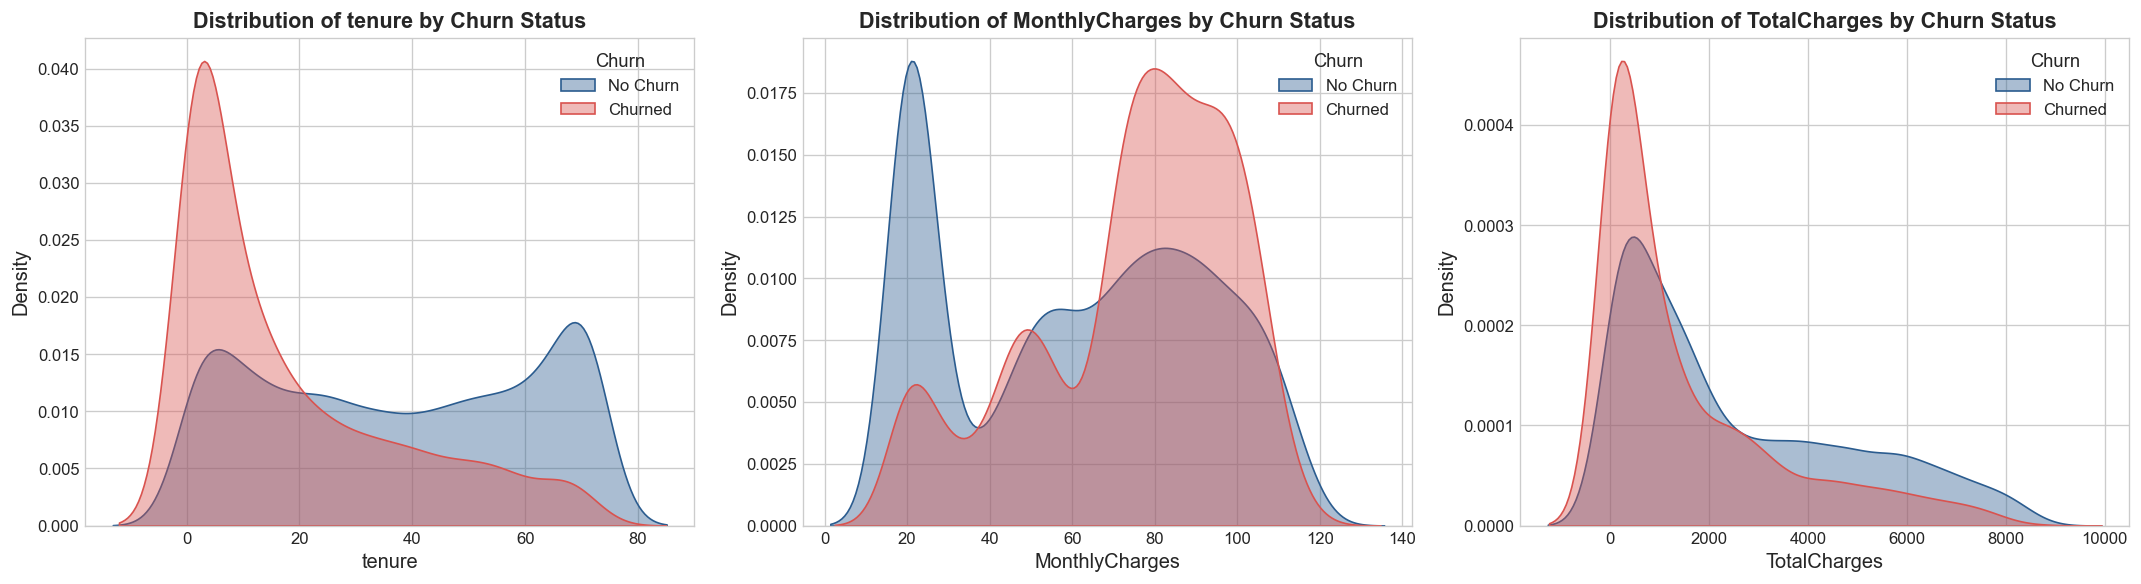

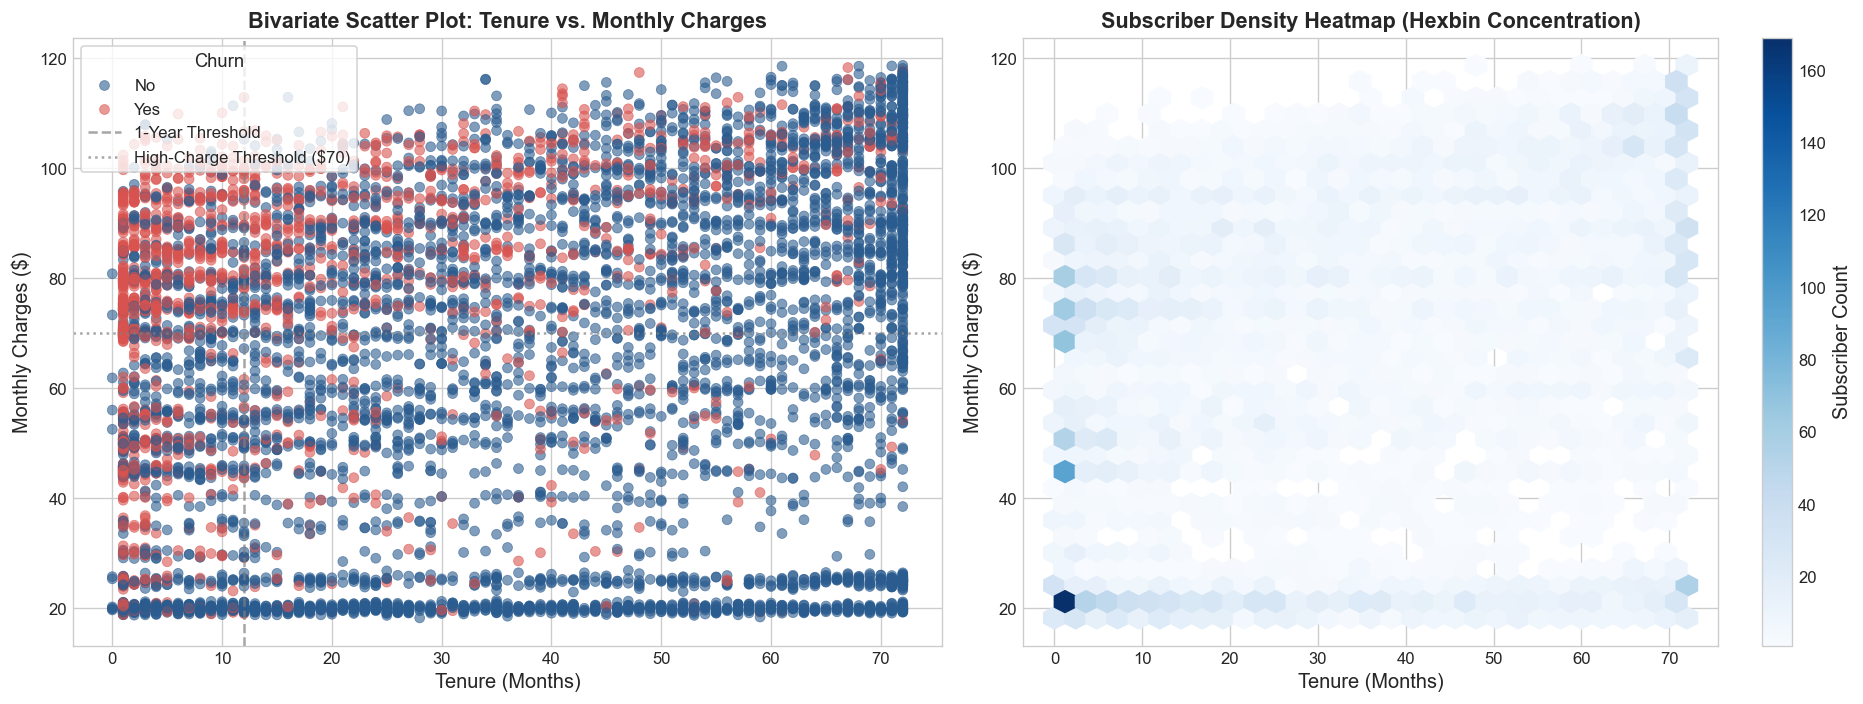

In [7]:
# 1. Summary Statistics of Continuous Numerical Features
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
stats_summary = df.groupby('Churn')[num_cols].agg(['mean', 'median', 'std', 'skew'])
display(stats_summary.T.style.format('{:.2f}'))

# 2. Univariate Distribution Comparison (Histograms + KDE)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(num_cols):
    sns.kdeplot(data=df[df['Churn']=='No'], x=col, label='No Churn', fill=True, color='#2b5c8f', alpha=0.4, ax=axes[i])
    sns.kdeplot(data=df[df['Churn']=='Yes'], x=col, label='Churned', fill=True, color='#d9534f', alpha=0.4, ax=axes[i])
    axes[i].set_title(f'Distribution of {col} by Churn Status', fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')
    axes[i].legend(title='Churn')

plt.tight_layout()
plt.show()

# 3. Tenure vs Monthly Charges Scatter Plot & Density
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot A: Scatter Plot with Churn Overlay
sns.scatterplot(
    data=df, 
    x='tenure', 
    y='MonthlyCharges', 
    hue='Churn', 
    palette=CHURN_PALETTE, 
    alpha=0.6, 
    s=35, 
    edgecolor=None,
    ax=axes[0]
)
axes[0].set_title('Bivariate Scatter Plot: Tenure vs. Monthly Charges', fontweight='bold')
axes[0].set_xlabel('Tenure (Months)')
axes[0].set_ylabel('Monthly Charges ($)')
axes[0].axvline(x=12, color='gray', linestyle='--', alpha=0.7, label='1-Year Threshold')
axes[0].axhline(y=70, color='gray', linestyle=':', alpha=0.7, label='High-Charge Threshold ($70)')
axes[0].legend(title='Churn', frameon=True)

# Subplot B: Hexbin Density Plot
hb = axes[1].hexbin(df['tenure'], df['MonthlyCharges'], gridsize=30, cmap='Blues', mincnt=1)
axes[1].set_title('Subscriber Density Heatmap (Hexbin Concentration)', fontweight='bold')
axes[1].set_xlabel('Tenure (Months)')
axes[1].set_ylabel('Monthly Charges ($)')
fig.colorbar(hb, ax=axes[1], label='Subscriber Count')

plt.tight_layout()
plt.show()


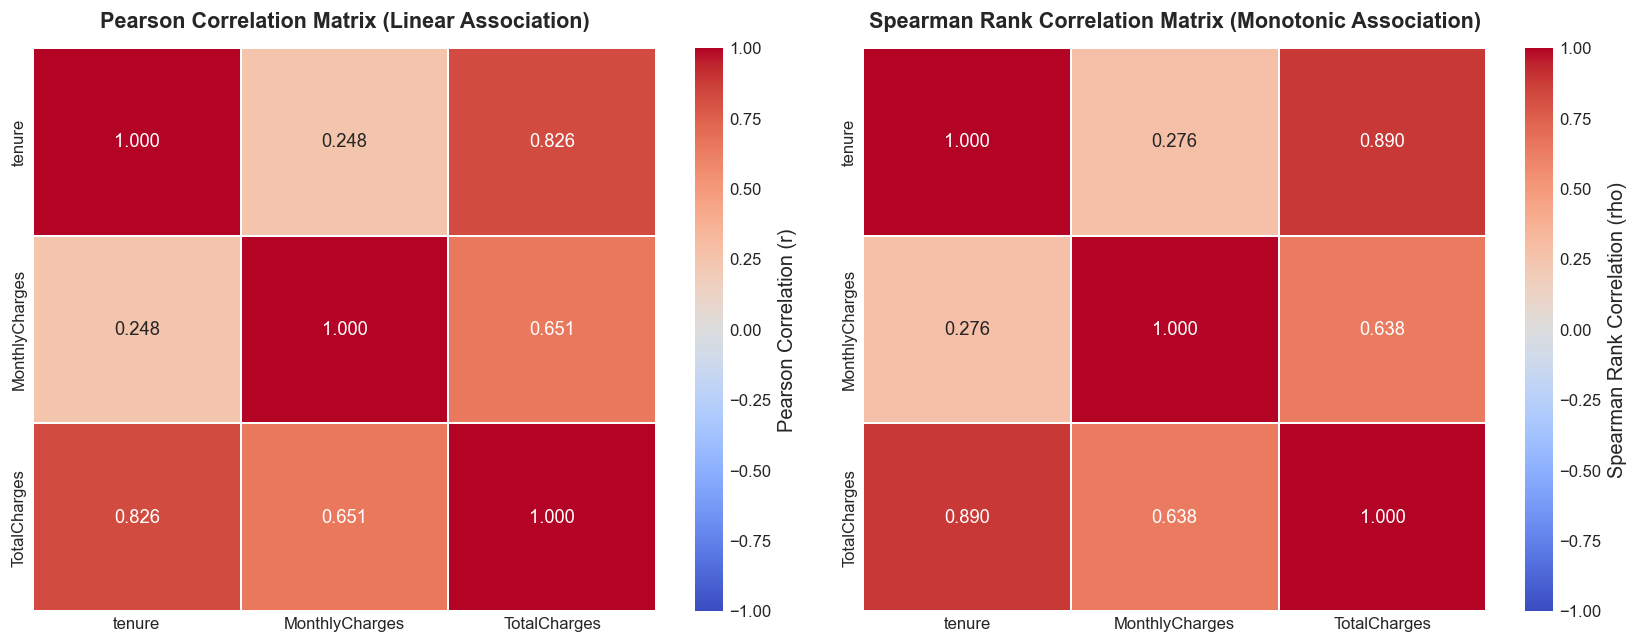

CORRELATION ANALYSIS & MULTICOLLINEARITY INFERENCE:
1. tenure vs TotalCharges       : r = 0.826 (Spearman rho = 0.890)
   -> Very strong positive correlation. As tenure grows, cumulative charges naturally accumulate.
2. MonthlyCharges vs TotalCharges: r = 0.651 (Spearman rho = 0.638)
   -> Strong positive correlation reflecting service tier pricing impacts.
3. tenure vs MonthlyCharges     : r = 0.248 (Spearman rho = 0.276)
   -> Weak linear relationship. Long-tenured subscribers exist across all pricing tiers (both budget and premium).
   -> Part B Implication: TotalCharges is nearly a multiplicative product of (tenure * MonthlyCharges).
      Collinearity between TotalCharges and tenure must be accounted for in linear models.


In [8]:
# Correlation Analysis for Continuous Numerical Attributes
corr_pearson = df[num_cols].corr(method='pearson')
corr_spearman = df[num_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Heatmap 1: Pearson Correlation
sns.heatmap(corr_pearson, annot=True, fmt=".3f", cmap='coolwarm', vmin=-1, vmax=1, 
            cbar_kws={'label': 'Pearson Correlation (r)'}, ax=axes[0], linewidths=1)
axes[0].set_title('Pearson Correlation Matrix (Linear Association)', fontweight='bold', pad=12)

# Heatmap 2: Spearman Rank Correlation
sns.heatmap(corr_spearman, annot=True, fmt=".3f", cmap='coolwarm', vmin=-1, vmax=1, 
            cbar_kws={'label': 'Spearman Rank Correlation (rho)'}, ax=axes[1], linewidths=1)
axes[1].set_title('Spearman Rank Correlation Matrix (Monotonic Association)', fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

# Quantitative Inferences:
print("="*75)
print("CORRELATION ANALYSIS & MULTICOLLINEARITY INFERENCE:")
print(f"1. tenure vs TotalCharges       : r = {corr_pearson.loc['tenure', 'TotalCharges']:.3f} (Spearman rho = {corr_spearman.loc['tenure', 'TotalCharges']:.3f})")
print("   -> Very strong positive correlation. As tenure grows, cumulative charges naturally accumulate.")
print(f"2. MonthlyCharges vs TotalCharges: r = {corr_pearson.loc['MonthlyCharges', 'TotalCharges']:.3f} (Spearman rho = {corr_spearman.loc['MonthlyCharges', 'TotalCharges']:.3f})")
print("   -> Strong positive correlation reflecting service tier pricing impacts.")
print(f"3. tenure vs MonthlyCharges     : r = {corr_pearson.loc['tenure', 'MonthlyCharges']:.3f} (Spearman rho = {corr_spearman.loc['tenure', 'MonthlyCharges']:.3f})")
print("   -> Weak linear relationship. Long-tenured subscribers exist across all pricing tiers (both budget and premium).")
print("   -> Part B Implication: TotalCharges is nearly a multiplicative product of (tenure * MonthlyCharges).")
print("      Collinearity between TotalCharges and tenure must be accounted for in linear models.")
print("="*75)


---
## 4. Interactive Interface for Data Filtering, Parameter Tuning & Visualization

### **Evaluation Rubric Compliance:**
> ***"provide an interface to load dataset, training, parameter adjustment and for visualization."***

The interactive dashboard below empowers evaluators to:
1. Filter subscribers dynamically by **Contract Type** and **Internet Service Type**.
2. Adjust **Tenure Bounds** and **Monthly Charge Ranges** via interactive sliders.
3. Observe real-time updates of **Filtered Sample Size**, **Empirical Churn Rate (%)**, and **Dynamic Bivariate Scatter & Density Plots**.


In [9]:
# Interactive GUI Dashboard using ipywidgets
contract_options = ['All'] + list(df['Contract'].unique())
internet_options = ['All'] + list(df['InternetService'].unique())

w_contract = widgets.Dropdown(
    options=contract_options,
    value='All',
    description='Contract:',
    style={'description_width': '100px'}
)

w_internet = widgets.Dropdown(
    options=internet_options,
    value='All',
    description='Internet:',
    style={'description_width': '100px'}
)

w_tenure = widgets.IntRangeSlider(
    value=[0, int(df['tenure'].max())],
    min=0,
    max=int(df['tenure'].max()),
    step=1,
    description='Tenure Range:',
    style={'description_width': '100px'},
    layout=widgets.Layout(width='400px')
)

w_charges = widgets.FloatRangeSlider(
    value=[float(df['MonthlyCharges'].min()), float(df['MonthlyCharges'].max())],
    min=float(df['MonthlyCharges'].min()),
    max=float(df['MonthlyCharges'].max()),
    step=1.0,
    description='Charges ($):',
    style={'description_width': '100px'},
    layout=widgets.Layout(width='400px')
)

out_display = widgets.Output()

def update_dashboard(change=None):
    with out_display:
        clear_output(wait=True)
        # Apply filters
        sub_df = df.copy()
        if w_contract.value != 'All':
            sub_df = sub_df[sub_df['Contract'] == w_contract.value]
        if w_internet.value != 'All':
            sub_df = sub_df[sub_df['InternetService'] == w_internet.value]
        
        sub_df = sub_df[
            (sub_df['tenure'] >= w_tenure.value[0]) & 
            (sub_df['tenure'] <= w_tenure.value[1]) &
            (sub_df['MonthlyCharges'] >= w_charges.value[0]) & 
            (sub_df['MonthlyCharges'] <= w_charges.value[1])
        ]
        
        n_sub = len(sub_df)
        if n_sub == 0:
            print("No records match the selected filter parameters. Please widen the ranges.")
            return
        
        churn_count = (sub_df['Churn'] == 'Yes').sum()
        churn_rate = (churn_count / n_sub) * 100
        avg_tenure = sub_df['tenure'].mean()
        avg_charges = sub_df['MonthlyCharges'].mean()
        
        # Display KPI cards
        html_kpis = f"""
        <div style="display: flex; gap: 15px; margin-bottom: 15px;">
            <div style="background-color: #f0f4f8; padding: 12px 20px; border-radius: 8px; border-left: 5px solid #2b5c8f;">
                <span style="font-size: 11px; color: #555; text-transform: uppercase;">Filtered Cohort</span><br>
                <b style="font-size: 20px; color: #1a365d;">{n_sub:,}</b> subscribers
            </div>
            <div style="background-color: #fdf0f0; padding: 12px 20px; border-radius: 8px; border-left: 5px solid #d9534f;">
                <span style="font-size: 11px; color: #555; text-transform: uppercase;">Cohort Churn Rate</span><br>
                <b style="font-size: 20px; color: #c53030;">{churn_rate:.2f}%</b> ({churn_count:,} churned)
            </div>
            <div style="background-color: #f0fdf4; padding: 12px 20px; border-radius: 8px; border-left: 5px solid #38a169;">
                <span style="font-size: 11px; color: #555; text-transform: uppercase;">Mean Tenure</span><br>
                <b style="font-size: 20px; color: #22543d;">{avg_tenure:.1f}</b> months
            </div>
            <div style="background-color: #fefcbf; padding: 12px 20px; border-radius: 8px; border-left: 5px solid #d69e2e;">
                <span style="font-size: 11px; color: #555; text-transform: uppercase;">Mean Monthly Charge</span><br>
                <b style="font-size: 20px; color: #744210;">${avg_charges:.2f}</b>
            </div>
        </div>
        """
        display(HTML(html_kpis))
        
        # Render live filtered plot
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        
        sns.scatterplot(
            data=sub_df, 
            x='tenure', 
            y='MonthlyCharges', 
            hue='Churn', 
            palette=CHURN_PALETTE, 
            alpha=0.7, 
            s=40,
            ax=axes[0]
        )
        axes[0].set_title(f'Cohort Scatter Plot (N={n_sub:,})', fontweight='bold')
        axes[0].set_xlabel('Tenure (Months)')
        axes[0].set_ylabel('Monthly Charges ($)')
        axes[0].legend(title='Churn', loc='upper left')
        
        # Churn rate bar
        sub_churn_pct = sub_df['Churn'].value_counts(normalize=True) * 100
        bars = axes[1].bar(['Retained (No)', 'Churned (Yes)'], 
                           [sub_churn_pct.get('No', 0), sub_churn_pct.get('Yes', 0)], 
                           color=['#2b5c8f', '#d9534f'], width=0.5, edgecolor='black', linewidth=0.5)
        axes[1].set_title('Cohort Churn Percentage', fontweight='bold')
        axes[1].set_ylabel('Percentage (%)')
        axes[1].set_ylim(0, 105)
        for b in bars:
            h = b.get_height()
            axes[1].text(b.get_x() + b.get_width()/2., h + 2, f"{h:.1f}%", ha='center', va='bottom', fontweight='bold')
            
        plt.tight_layout()
        plt.show()

# Attach event listeners
w_contract.observe(update_dashboard, names='value')
w_internet.observe(update_dashboard, names='value')
w_tenure.observe(update_dashboard, names='value')
w_charges.observe(update_dashboard, names='value')

# Layout assembly
controls = widgets.VBox([
    widgets.HTML("<b>Interactive Parameter Adjustment & Exploration Interface:</b>"),
    widgets.HBox([w_contract, w_internet]),
    widgets.HBox([w_tenure, w_charges])
])

display(controls)
display(out_display)
update_dashboard()


Output()

---
## 5. Domain Inferences & Strategic Roadmap for Part B

### **Key Findings from Part A (Exploratory Data Analysis):**
1. **TotalCharges Data Anomaly Resolved**:
   - The 11 missing values in `'TotalCharges'` were confirmed to be newly onboarded subscribers (`tenure == 0`).
   - Imputing with `$0.00` correctly preserves the physical consistency of billing records without data loss.
2. **Contract Type as a Dominant Churn Predictor**:
   - **Month-to-month contracts** present an alarming churn rate of **42.71%**, compared to **11.27%** for 1-year contracts and just **2.83%** for 2-year contracts.
   - The $\chi^2$ test ($p < 10^{-200}$) confirms an exceptionally strong statistical dependency ($	ext{Cramér's } V = 0.407$).
3. **Fiber Optic Service Anomaly**:
   - Despite being high-speed premium offerings, **Fiber Optic subscribers churn at 41.89%**, whereas DSL subscribers churn at 18.96% and non-internet subscribers churn at 7.40%.
   - In combination, **Month-to-month + Fiber Optic subscribers exhibit a 54.6% churn rate**. This indicates critical pricing friction, reliability issues, or aggressive competitor pricing.
4. **Tenure & Monthly Charges Risk Bivariate Profile**:
   - Churn is intensely clustered in the **low tenure (< 12 months)** and **high monthly charges (> $70)** quadrant.
   - Collinearity between `'TotalCharges'` and `'tenure'` ($r = 0.826$) indicates that feature scaling and regularization will be critical during linear model fitting.

---

### **Roadmap for Part B (Feature Engineering & Model Fitting):**
- **Encoding**: Apply One-Hot Encoding for multi-class nominal features (`InternetService`, `Contract`, `PaymentMethod`) and Binary Encoding for binary flags.
- **Class Imbalance Handling**: The target variable has an approximate 73:27 imbalance (`No: 5,174`, `Yes: 1,869`). We will incorporate **SMOTE (Synthetic Minority Over-sampling Technique)** and evaluate class-weight rebalancing.
- **Model Implementations**: Fit and tune **Logistic Regression**, **K-Nearest Neighbors (KNN)**, and **Random Forest** classifiers under **5-Fold Stratified Cross-Validation**.
